# 2. Register and Rydberg-atom interactions

A short companion to [Register and Rydberg-Atom Interactions](https://docs.pasqal.com/pulser/register/), the second core tutorial in the pre-reading PDF. We create atom arrays and visualize how geometry affects interactions.

Run `uv sync --locked` in the repository terminal, select `.venv/bin/python` as the kernel, and run the cells in order. All examples are local.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pulser import AnalogDevice, Register

## Create a register

A register maps qubit names to positions in micrometers. You can supply those positions directly or use a built-in pattern. `from_coordinates` centers the positions by default; translating the whole array does not change pairwise distances.

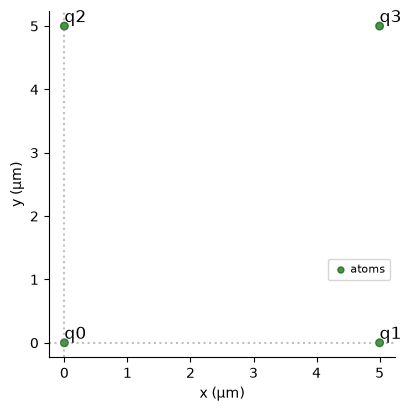

Centered positions: {'q0': array([-2.5, -2.5]), 'q1': array([ 2.5, -2.5]), 'q2': array([-2.5,  2.5]), 'q3': array([2.5, 2.5])}


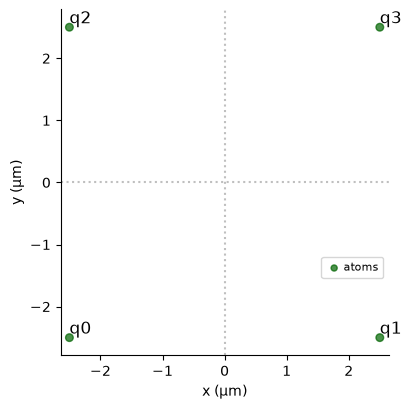

In [2]:
qubits = {"q0": [0, 0], "q1": [5, 0], "q2": [0, 5], "q3": [5, 5]}
manual = Register(qubits)
manual.draw()

centered = Register.from_coordinates(list(qubits.values()), prefix="q")
print("Centered positions:", centered.qubits)

square = Register.square(2, spacing=5, prefix="q")
square.draw()

## Distance sets the interaction strength

When both atoms are in Rydberg states, their interaction strength scales as $C_6/R^6$. Doubling their separation reduces the interaction by a factor of 64. Here Pulser's `interaction_coeff` already includes the conversion to angular-frequency units.

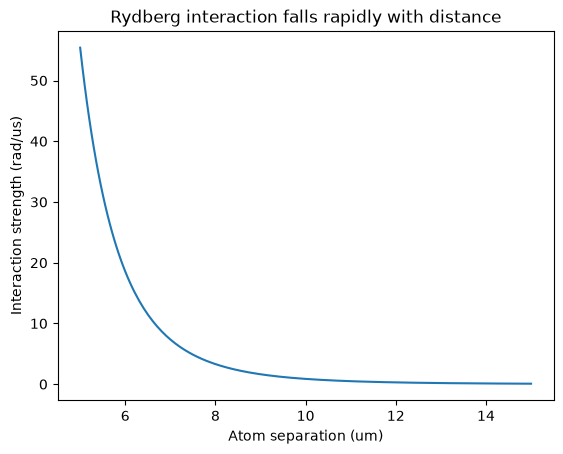

In [3]:
distances = np.linspace(5, 15, 200)
interaction = AnalogDevice.interaction_coeff / distances**6

plt.figure()
plt.plot(distances, interaction)
plt.xlabel("Atom separation (um)")
plt.ylabel("Interaction strength (rad/us)")
plt.title("Rydberg interaction falls rapidly with distance")
plt.show()

## Estimate the blockade radius

If the interaction is much stronger than a resonant drive, exciting both nearby atoms is suppressed: this is the **Rydberg blockade**. The blockade radius marks where interaction and drive strengths are equal; it is a useful scale, not a sharp physical cutoff. A stronger drive gives a smaller blockade radius.

In [4]:
omega = 1.0
radius = AnalogDevice.rydberg_blockade_radius(omega)
print(f"For a drive of {omega:.1f} rad/us, blockade radius = {radius:.2f} um")

target_radius = 8.0
required_omega = AnalogDevice.rabi_from_blockade(target_radius)
print(f"For a radius of {target_radius:.1f} um, drive = {required_omega:.2f} rad/us")

For a drive of 1.0 rad/us, blockade radius = 9.76 um
For a radius of 8.0 um, drive = 3.30 rad/us


## Visualize a connectivity graph

Edges connect atoms separated by less than the chosen blockade radius. Each circle has **half** that radius, so overlapping circles indicate connected atoms. This triangular array uses 6 um spacing and a 7 um blockade radius.

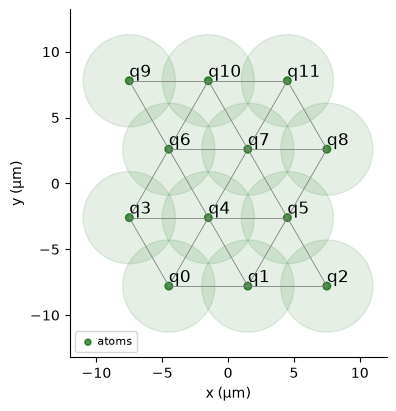

In [5]:
triangular = Register.triangular_lattice(
    rows=4, atoms_per_row=3, spacing=6, prefix="q"
)
triangular.draw(blockade_radius=7, draw_half_radius=True, draw_graph=True)

## Why register design matters

- Design positions together with the pulse amplitude and detuning, not in isolation.
- Distances can encode pairwise penalties, but arbitrary QUBO couplings cannot generally be reproduced by a 2D atom array: distances must obey geometry and interactions follow $1/R^6$.
- A blockade graph is a useful approximation for problems such as maximum independent set. Atoms outside the radius still interact, just more weakly.